In [ ]:
!pip install -Uq tensorflow tensorflow-datasets importlib-resources

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 95.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 18.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
grpcio-tools 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.36.2 which is incompatible.
google-cloud-aiplatform 2.3.0 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<7.0.0,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
ydf-tf 2.20.0 requires tensorflow==2.20.0, but you have tensorflow 2.21.0 which is incompatible.
google-ai-generativelanguage 0

## 1. Setup and configuration

In [ ]:
import os, gc, json, time, math
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, classification_report

# ---------------- global configuration (identical for all experiments) ----------------
SEED        = 42
IMG         = 224
NUM_CLASSES = 5
BATCH       = 32
EPOCHS_HEAD = 5        # phase 1: backbone frozen, train attention + classifier
EPOCHS_FT   = 5        # phase 2: unfreeze conv5_x (BN frozen), fine-tune
LR_HEAD     = 1e-3
LR_FT       = 1e-4
DROPOUT     = 0.3
RED         = 16       # channel-attention reduction ratio r (fixed, not ablated)
WEIGHTS     = "imagenet"
OUT         = "outputs"
for d in ["results", "weights", "figures"]:
    os.makedirs(f"{OUT}/{d}", exist_ok=True)

keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "savefig.dpi": 600, "ps.fonttype": 42})
# All figures are written as EPS @ 600 dpi to outputs/figures/. EPS has no transparency, so heat-map overlays are alpha-blended manually.
print("TF", tf.__version__, "| Keras", keras.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TF 2.21.0 | Keras 3.13.2 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Dataset
`tf_flowers` has 3,670 images in 5 classes.

In [ ]:
import tensorflow_datasets as tfds

ds_full, info = tfds.load("tf_flowers", split="train", as_supervised=True, with_info=True)
CLASS_NAMES = info.features["label"].names
print("Classes:", CLASS_NAMES)

def _resize(img, lab):
    img = tf.image.resize(img, (IMG, IMG), antialias=True)
    return tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8), lab

X_all, y_all = [], []
for img, lab in tfds.as_numpy(ds_full.map(_resize, num_parallel_calls=tf.data.AUTOTUNE)):
    X_all.append(img); y_all.append(lab)
X_all = np.stack(X_all); y_all = np.array(y_all)
print("All images:", X_all.shape, "| class counts:", np.bincount(y_all))

# ---- stratified 70 / 15 / 15, fixed once ----
split_file = f"{OUT}/split.npz"
if os.path.exists(split_file):
    s = np.load(split_file); tr_idx, va_idx, te_idx = s["tr"], s["va"], s["te"]
else:
    idx = np.arange(len(y_all))
    tr_idx, tmp = train_test_split(idx, test_size=0.30, stratify=y_all, random_state=SEED)
    va_idx, te_idx = train_test_split(tmp, test_size=0.50, stratify=y_all[tmp], random_state=SEED)
    np.savez(split_file, tr=tr_idx, va=va_idx, te=te_idx)

assert not (set(tr_idx) & set(va_idx)) and not (set(tr_idx) & set(te_idx)) and not (set(va_idx) & set(te_idx))
X_train, y_train = X_all[tr_idx], y_all[tr_idx]
X_val,   y_val   = X_all[va_idx], y_all[va_idx]
X_test,  y_test  = X_all[te_idx], y_all[te_idx]
print(f"train {len(y_train)} | val {len(y_val)} | test {len(y_test)}")
print("test class counts:", dict(zip(CLASS_NAMES, np.bincount(y_test))))

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.HBRPOI_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
All images: (3670, 224, 224, 3) | class counts: [898 633 799 699 641]
train 2569 | val 550 | test 551
test class counts: {'dandelion': np.int64(135), 'daisy': np.int64(95), 'tulips': np.int64(120), 'sunflowers': np.int64(105), 'roses': np.int64(96)}


### 2.1 Preprocessing and augmentation

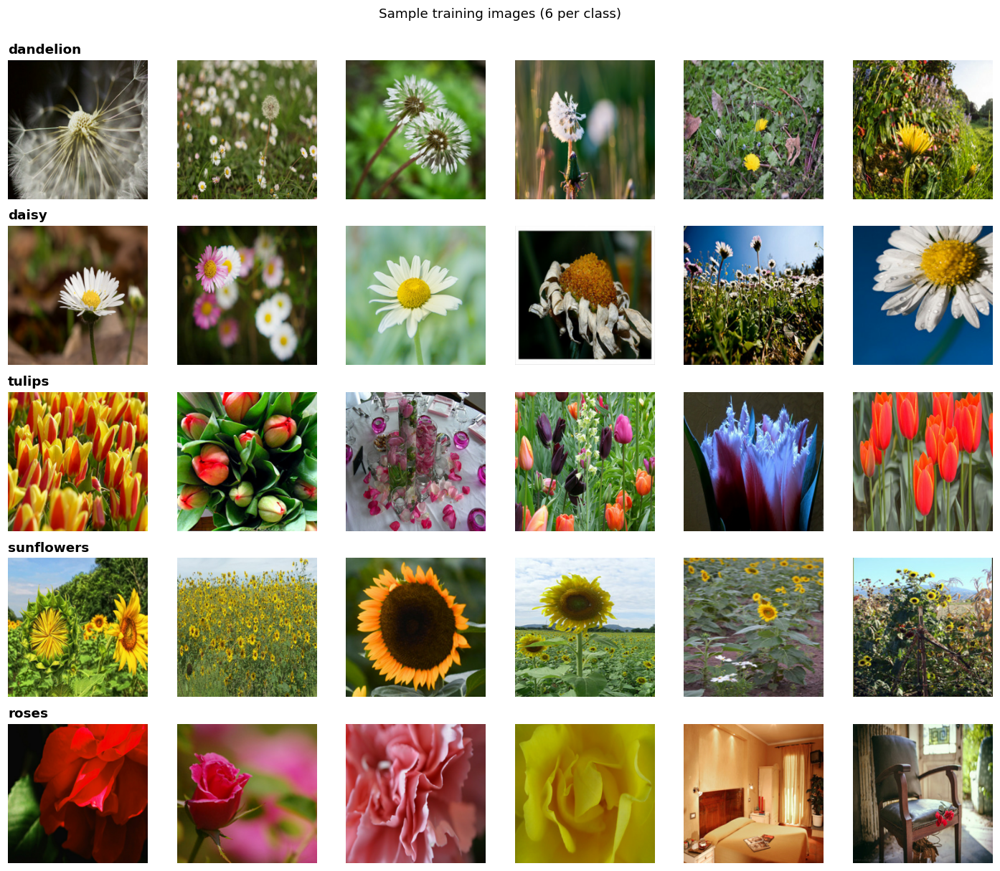

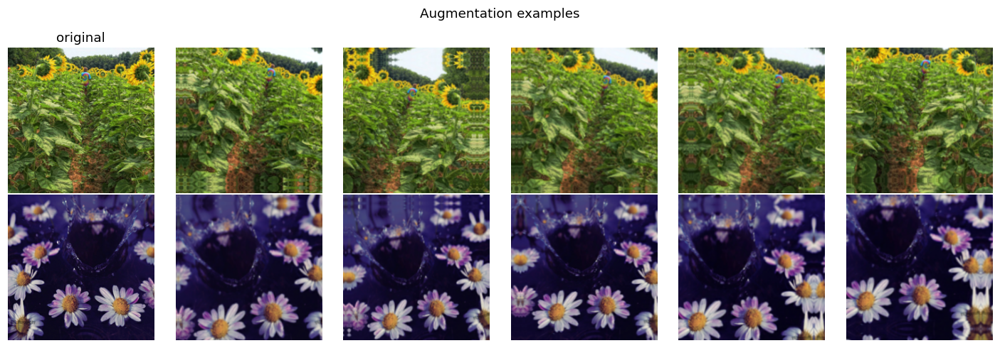

In [ ]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),            # ≈ ±18°
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.10, 0.10),
    layers.RandomContrast(0.10),
], name="augmentation")

AUTOTUNE = tf.data.AUTOTUNE

def make_ds(X, y, training):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH)
    def f(x, lab):
        x = tf.cast(x, tf.float32)
        if training:
            x = augment(x, training=True)
        x = preprocess_input(x)
        return x, tf.one_hot(lab, NUM_CLASSES)
    return ds.map(f, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

train_ds = make_ds(X_train, y_train, True)
val_ds   = make_ds(X_val,   y_val,   False)
test_ds  = make_ds(X_test,  y_test,  False)

def prep(x_uint8):
    """uint8 images (N,224,224,3) -> ResNet50-preprocessed float32."""
    return preprocess_input(np.asarray(x_uint8, dtype=np.float32).copy())

# ---- Required visualization 1: sample images from all five classes ----
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(13, 11))
rng = np.random.RandomState(0)
for c in range(NUM_CLASSES):
    ids = rng.choice(np.where(y_train == c)[0], 6, replace=False)
    for j, i in enumerate(ids):
        axes[c, j].imshow(X_train[i]); axes[c, j].axis("off")
    axes[c, 0].set_title(CLASS_NAMES[c], loc="left", fontsize=12, fontweight="bold")
plt.suptitle("Sample training images (6 per class)", y=1.0); plt.tight_layout()
plt.savefig(f"{OUT}/figures/01_samples.eps", bbox_inches="tight", dpi=600, format="eps"); plt.show()

# ---- show what the augmentation does ----
fig, axes = plt.subplots(2, 6, figsize=(13, 4.5))
img0 = X_train[:1].astype(np.float32)
axes[0, 0].imshow(X_train[0]); axes[0, 0].set_title("original"); axes[0, 0].axis("off")
for j in range(1, 6):
    axes[0, j].imshow(np.clip(augment(img0, training=True)[0].numpy(), 0, 255).astype("uint8")); axes[0, j].axis("off")
img1 = X_train[1:2].astype(np.float32)
axes[1, 0].imshow(X_train[1]); axes[1, 0].axis("off")
for j in range(1, 6):
    axes[1, j].imshow(np.clip(augment(img1, training=True)[0].numpy(), 0, 255).astype("uint8")); axes[1, j].axis("off")
plt.suptitle("Augmentation examples"); plt.tight_layout(); plt.show()

## 3. Attention modules


In [ ]:
class ChannelAttention(layers.Layer):
    """M_c(F) = sigmoid(W2 relu(W1 GAP(F))).  Identical to a Squeeze-and-Excitation block."""
    def __init__(self, reduction=RED, **kw):
        super().__init__(**kw); self.reduction = reduction
    def build(self, input_shape):
        C = int(input_shape[-1]); hidden = max(C // self.reduction, 1)
        self.fc1 = layers.Dense(hidden, activation="relu")
        self.fc2 = layers.Dense(C, activation="sigmoid")
        self.fc1.build((None, C)); self.fc2.build((None, hidden))
        super().build(input_shape)
    def channel_weights(self, x):
        return self.fc2(self.fc1(tf.reduce_mean(x, axis=[1, 2])))
    def call(self, x):
        return x * self.channel_weights(x)[:, None, None, :]


class SpatialAttention(layers.Layer):
    """M_s(F) = sigmoid(Conv_kxk([mean_c(F) || max_c(F)]))."""
    def __init__(self, kernel_size=7, **kw):
        super().__init__(**kw); self.kernel_size = kernel_size
    def build(self, input_shape):
        self.conv = layers.Conv2D(1, self.kernel_size, padding="same", activation="sigmoid")
        self.conv.build(tuple(input_shape)[:-1] + (2,))
        super().build(input_shape)
    def spatial_map(self, x):
        s = tf.concat([tf.reduce_mean(x, -1, keepdims=True), tf.reduce_max(x, -1, keepdims=True)], axis=-1)
        return self.conv(s)
    def call(self, x):
        return x * self.spatial_map(x)


class ChannelSpatial(layers.Layer):
    """Sequential channel+spatial attention. order='cs': F->Mc->Ms ; order='sc': F->Ms->Mc."""
    def __init__(self, order="cs", kernel_size=7, reduction=RED, **kw):
        super().__init__(**kw)
        assert order in ("cs", "sc")
        self.order = order
        self.ca = ChannelAttention(reduction)
        self.sa = SpatialAttention(kernel_size)
    def call(self, x):
        return self.sa(self.ca(x)) if self.order == "cs" else self.ca(self.sa(x))
    def channel_weights(self, x):
        return self.ca.channel_weights(x if self.order == "cs" else self.sa(x))
    def spatial_map(self, x):
        return self.sa.spatial_map(self.ca(x) if self.order == "cs" else x)


class SelfAttention(layers.Layer):
    """Non-local style self-attention: F_SA = F + gamma * reshape(softmax(QK^T/sqrt(d)) V)."""
    def build(self, input_shape):
        self.H, self.W, self.C = int(input_shape[1]), int(input_shape[2]), int(input_shape[3])
        self.d  = max(self.C // 8, 1)       # query/key dimension
        self.dv = max(self.C // 2, 1)       # value dimension
        self.q = layers.Dense(self.d, use_bias=False)
        self.k = layers.Dense(self.d, use_bias=False)
        self.v = layers.Dense(self.dv, use_bias=False)
        self.o = layers.Dense(self.C, use_bias=False)
        for l, i, o in [(self.q, self.C, self.d), (self.k, self.C, self.d), (self.v, self.C, self.dv), (self.o, self.dv, self.C)]:
            l.build((None, i))
        self.gamma = self.add_weight(name="gamma", shape=(), initializer="zeros", trainable=True)
        super().build(input_shape)
    def _flat(self, x):
        return tf.reshape(x, [-1, self.H * self.W, self.C])
    def _attn(self, X):
        Q, K = self.q(X), self.k(X)
        return tf.nn.softmax(tf.matmul(Q, K, transpose_b=True) / math.sqrt(self.d), axis=-1)
    def attention_matrix(self, x):
        return self._attn(self._flat(x))
    def call(self, x):
        X = self._flat(x)
        Y = self.o(tf.matmul(self._attn(X), self.v(X)))
        return x + self.gamma * tf.reshape(Y, [-1, self.H, self.W, self.C])


class CombinedAttention(layers.Layer):
    """Channel -> Spatial -> Self-attention (model A5)."""
    def __init__(self, kernel_size=7, reduction=RED, **kw):
        super().__init__(**kw)
        self.ca = ChannelAttention(reduction); self.sa = SpatialAttention(kernel_size); self.sat = SelfAttention()
    def call(self, x):
        return self.sat(self.sa(self.ca(x)))
    def channel_weights(self, x): return self.ca.channel_weights(x)
    def spatial_map(self, x):     return self.sa.spatial_map(self.ca(x))
    def attention_matrix(self, x): return self.sat.attention_matrix(self.sa(self.ca(x)))


class ECA(layers.Layer):
    """Efficient Channel Attention: 1-D conv over the pooled channel descriptor, no dimensionality reduction."""
    def __init__(self, gamma=2, b=1, **kw):
        super().__init__(**kw); self.g, self.b = gamma, b
    def build(self, input_shape):
        C = int(input_shape[-1]); t = int(abs((math.log2(C) + self.b) / self.g))
        self.k = t if t % 2 else t + 1
        self.conv = layers.Conv1D(1, self.k, padding="same", use_bias=False, activation="sigmoid")
        self.conv.build((None, C, 1))
        super().build(input_shape)
    def channel_weights(self, x):
        z = tf.reduce_mean(x, axis=[1, 2])[..., None]          # (B, C, 1)
        return tf.squeeze(self.conv(z), -1)
    def call(self, x):
        return x * self.channel_weights(x)[:, None, None, :]


class CBAM(layers.Layer):
    """CBAM: channel attention (avg + max descriptors, shared MLP) followed by 7x7 spatial attention."""
    def __init__(self, reduction=RED, kernel_size=7, **kw):
        super().__init__(**kw); self.reduction, self.kernel_size = reduction, kernel_size
    def build(self, input_shape):
        C = int(input_shape[-1]); hidden = max(C // self.reduction, 1)
        self.fc1 = layers.Dense(hidden, activation="relu"); self.fc2 = layers.Dense(C)
        self.fc1.build((None, C)); self.fc2.build((None, hidden))
        self.sa = SpatialAttention(self.kernel_size)
        super().build(input_shape)
    def channel_weights(self, x):
        a, m = tf.reduce_mean(x, axis=[1, 2]), tf.reduce_max(x, axis=[1, 2])
        return tf.sigmoid(self.fc2(self.fc1(a)) + self.fc2(self.fc1(m)))
    def call(self, x):
        return self.sa(x * self.channel_weights(x)[:, None, None, :])
    def spatial_map(self, x):
        return self.sa.spatial_map(x * self.channel_weights(x)[:, None, None, :])


class CoordinateAttention(layers.Layer):
    """Coordinate Attention (Hou et al., 2021)."""
    def __init__(self, reduction=32, **kw):
        super().__init__(**kw); self.reduction = reduction
    def build(self, input_shape):
        self.H, self.W, C = int(input_shape[1]), int(input_shape[2]), int(input_shape[3])
        mip = max(8, C // self.reduction)
        self.conv1  = layers.Conv2D(mip, 1); self.bn = layers.BatchNormalization()
        self.conv_h = layers.Conv2D(C, 1, activation="sigmoid"); self.conv_w = layers.Conv2D(C, 1, activation="sigmoid")
        self.conv1.build((None, self.H + self.W, 1, C)); self.bn.build((None, self.H + self.W, 1, mip))
        self.conv_h.build((None, self.H, 1, mip)); self.conv_w.build((None, self.W, 1, mip))
        super().build(input_shape)
    def _gates(self, x, training=None):
        xh = tf.reduce_mean(x, axis=2, keepdims=True)                                # (B,H,1,C)
        xw = tf.transpose(tf.reduce_mean(x, axis=1, keepdims=True), [0, 2, 1, 3])    # (B,W,1,C)
        y = self.bn(self.conv1(tf.concat([xh, xw], axis=1)), training=training)
        y = y * tf.nn.relu6(y + 3.0) / 6.0                                           # h-swish
        yh, yw = tf.split(y, [self.H, self.W], axis=1)
        return self.conv_h(yh), tf.transpose(self.conv_w(yw), [0, 2, 1, 3])          # (B,H,1,C), (B,1,W,C)
    def call(self, x, training=None):
        a_h, a_w = self._gates(x, training)
        return x * a_h * a_w
    def spatial_map(self, x):
        a_h, a_w = self._gates(x, False)
        return tf.reduce_mean(a_h * a_w, axis=-1, keepdims=True)


ATTN_BUILDERS = {
    "channel":  ChannelAttention,
    "se":       ChannelAttention,
    "spatial":  SpatialAttention,
    "cs":       lambda **kw: ChannelSpatial(order="cs", **kw),
    "sc":       lambda **kw: ChannelSpatial(order="sc", **kw),
    "self":     SelfAttention,
    "combined": CombinedAttention,
    "eca":      ECA,
    "cbam":     CBAM,
    "coord":    CoordinateAttention,
}
def A(kind, **kw):
    """Attention specification used in experiment definitions."""
    return (kind, kw)

In [ ]:
POS_SHAPES = {1: (56, 56, 256), 2: (28, 28, 512), 3: (14, 14, 1024), 4: (7, 7, 2048)}
rows = []
for kind in ATTN_BUILDERS:
    if kind == "se": continue
    row = {"module": kind}
    for p, (H, W, C) in POS_SHAPES.items():
        layer = ATTN_BUILDERS[kind]()
        y = layer(tf.random.normal((2, H, W, C)))
        assert y.shape == (2, H, W, C), (kind, p, y.shape)
        row[f"P{p} params"] = layer.count_params()
    rows.append(row)
print("All attention modules preserve tensor shape at P1..P4 ✔")
display(pd.DataFrame(rows).set_index("module").style.format("{:,}"))

rows = []
for p, (H, W, C) in POS_SHAPES.items():
    N = H * W
    rows.append({"position": f"P{p}", "H×W×C": f"{H}×{W}×{C}", "N=HW": N, "N×N entries": N * N,
                 "attn matrix / image (MB, fp32)": N * N * 4 / 2**20})
display(pd.DataFrame(rows).set_index("position").style.format({"N×N entries": "{:,}", "attn matrix / image (MB, fp32)": "{:.2f}"}))

All attention modules preserve tensor shape at P1..P4 ✔


,P1 params,P2 params,P3 params,P4 params
module,,,,
channel,"8,464","33,312","132,160","526,464"
spatial,99,99,99,99
cs,"8,563","33,411","132,259","526,563"
sc,"8,563","33,411","132,259","526,563"
self,"81,921","327,681","1,310,721","5,242,881"
combined,"90,484","361,092","1,442,980","5,769,444"
eca,5,5,5,7
cbam,"8,563","33,411","132,259","526,563"
coord,"6,696","25,680","100,512","397,632"


,H×W×C,N=HW,N×N entries,"attn matrix / image (MB, fp32)"
position,,,,
P1,56×56×256,3136,"9,834,496",37.52
P2,28×28×512,784,"614,656",2.34
P3,14×14×1024,196,"38,416",0.15
P4,7×7×2048,49,"2,401",0.01


## 4. ResNet50 with attention

In [ ]:
STAGE_ENDS = ["conv2_block3_out", "conv3_block4_out", "conv4_block6_out", "conv5_block3_out"]

def build_model(spec=None, name="model", weights=WEIGHTS):
    """spec: {'P2': A('cs'), 'P3': A('self'), ...}  (empty/None -> baseline)."""
    spec = spec or {}
    keras.utils.set_random_seed(SEED)
    base = keras.applications.ResNet50(weights=weights, include_top=False, input_shape=(IMG, IMG, 3))
    inp = keras.Input((IMG, IMG, 3), name="image")
    x, prev = inp, base.input
    for i, end in enumerate(STAGE_ENDS, 1):
        stage = keras.Model(prev, base.get_layer(end).output, name=f"stage{i}")
        x = stage(x)
        if f"P{i}" in spec:
            kind, kw = spec[f"P{i}"]
            x = ATTN_BUILDERS[kind](name=f"attn_P{i}", **kw)(x)
        prev = base.get_layer(end).output
    x = layers.Activation("linear", name="final_features")(x)       # tensor used by Grad-CAM
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(DROPOUT, name="dropout")(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax", name="classifier")(x)
    return keras.Model(inp, out, name=name)

def set_phase(model, phase):
    """phase 'head': backbone frozen. phase 'finetune': conv5_x trainable (BN frozen)."""
    for i in range(1, 5):
        model.get_layer(f"stage{i}").trainable = False
    if phase == "finetune":
        s4 = model.get_layer("stage4"); s4.trainable = True
        for l in s4.layers:
            if isinstance(l, layers.BatchNormalization):
                l.trainable = False

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss=keras.losses.CategoricalCrossentropy(), metrics=["accuracy"])

def n_trainable(model): return int(sum(np.prod(w.shape) for w in model.trainable_weights))

# quick look at the baseline and one attention model
_m = build_model({"P3": A("cs")}, "demo")
print("Total params:", f"{_m.count_params():,}")
print("attn_P3 :", _m.get_layer("stage3").output.shape, "->", _m.get_layer("attn_P3").output.shape)
del _m; keras.backend.clear_session(); gc.collect()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Total params: 23,730,216
attn_P3 : (None, 14, 14, 1024) -> (None, 14, 14, 1024)


0

### 4.1 Training, evaluation and complexity measurement

In [ ]:
class BestTracker(keras.callbacks.Callback):
    """Keeps the weights of the epoch with the best validation accuracy across *both* phases."""
    def __init__(self): super().__init__(); self.best, self.weights, self.epoch = -1.0, None, -1; self.count = 0
    def on_epoch_end(self, epoch, logs=None):
        self.count += 1
        if logs["val_accuracy"] > self.best:
            self.best, self.weights, self.epoch = logs["val_accuracy"], self.model.get_weights(), self.count

def measure_inference_ms(model, repeats=4):
    batches = [xb for xb, _ in test_ds]
    f = tf.function(lambda x: model(x, training=False))
    for xb in (batches[0], batches[-1]): f(xb).numpy()          # warm-up (both batch shapes)
    t = []
    for _ in range(repeats):
        s = time.perf_counter()
        for xb in batches: f(xb).numpy()
        t.append((time.perf_counter() - s) / len(y_test))
    return 1000 * float(np.median(t))

def weights_path(name): return f"{OUT}/weights/{name}.weights.h5"
def results_path(name): return f"{OUT}/results/{name}.json"

def run_experiment(name, spec, force=False):
    if os.path.exists(results_path(name)) and not force:
        print(f"[skip] {name} (already done)"); return json.load(open(results_path(name)))
    print(f"\n{'='*80}\n{name}   spec={ {k: v for k, v in (spec or {}).items()} }\n{'='*80}")
    t0 = time.time()
    model = build_model(spec, name)
    shapes = {}
    for k in (spec or {}):
        i = int(k[1:])
        sin, sout = model.get_layer(f"stage{i}").output.shape, model.get_layer(f"attn_P{i}").output.shape
        assert tuple(sin) == tuple(sout), "attention changed the tensor shape!"
        shapes[k] = {"before": str(tuple(sin[1:])), "after": str(tuple(sout[1:]))}
    attn_params = int(sum(l.count_params() for l in model.layers if l.name.startswith("attn_")))

    tracker = BestTracker(); hist = {}
    for phase, epochs, lr in [("head", EPOCHS_HEAD, LR_HEAD), ("finetune", EPOCHS_FT, LR_FT)]:
        set_phase(model, phase); compile_model(model, lr)
        print(f"-- phase {phase}: trainable params = {n_trainable(model):,}")
        h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=[tracker], verbose=2).history
        for k, v in h.items(): hist.setdefault(k, []).extend([float(a) for a in v])
    trainable_ft = n_trainable(model)
    model.set_weights(tracker.weights)                       # restore best-validation epoch
    model.save_weights(weights_path(name))

    probs = model.predict(test_ds, verbose=0); y_pred = probs.argmax(1)
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
    _, _, f1c, _ = precision_recall_fscore_support(y_test, y_pred, average=None, labels=range(NUM_CLASSES), zero_division=0)
    acc = float((y_pred == y_test).mean())
    res = dict(name=name, spec={k: [v[0], v[1]] for k, v in (spec or {}).items()}, shapes=shapes, history=hist,
               best_val_acc=float(tracker.best), best_epoch=int(tracker.epoch),
               test_acc=acc, acc_ci95=float(1.96 * math.sqrt(acc * (1 - acc) / len(y_test))),
               precision=float(p), recall=float(r), f1=float(f1), per_class_f1=[float(a) for a in f1c],
               trainable_params=trainable_ft, total_params=int(model.count_params()), attn_params=attn_params,
               infer_ms=measure_inference_ms(model), y_pred=[int(a) for a in y_pred],
               train_time_s=float(time.time() - t0))
    json.dump(res, open(results_path(name), "w"))
    print(f"[{name}] test acc {acc:.4f} | macro-F1 {f1:.4f} | params {res['total_params']:,} | "
          f"{res['infer_ms']:.2f} ms/img | {res['train_time_s']/60:.1f} min")
    del model; keras.backend.clear_session(); gc.collect()
    return res

## 5. Experiment definitions

In [ ]:
EXPERIMENTS = {
    # ---- Exp 1: attention type, fixed at P3 ----
    "A0_baseline":     {},
    "A1_channel_P3":   {"P3": A("channel")},                 # = SE
    "A2_spatial_P3":   {"P3": A("spatial")},
    "A3_cs_P3":        {"P3": A("cs")},
    "A4_self_P3":      {"P3": A("self")},
    "A5_combined_P3":  {"P3": A("combined")},
    # ---- Exp 2: position, Channel->Spatial (A3 is the P3 entry) ----
    "B1_cs_P1":        {"P1": A("cs")},
    "B2_cs_P2":        {"P2": A("cs")},
    "B4_cs_P4":        {"P4": A("cs")},
    # ---- Exp 3: multiple positions ----
    "C1_cs_P3P4":      {"P3": A("cs"), "P4": A("cs")},
    "C2_cs_P2P3P4":    {"P2": A("cs"), "P3": A("cs"), "P4": A("cs")},
    # ---- Exp 4: order (A3 is Channel->Spatial) ----
    "D1_sc_P3":        {"P3": A("sc")},
    # ---- Exp 5: spatial kernel size (A3 is k=7) ----
    "E1_cs_k3_P3":     {"P3": A("cs", kernel_size=3)},
    "E2_cs_k5_P3":     {"P3": A("cs", kernel_size=5)},
    # ---- additional mechanisms at P3 ----
    "X1_eca_P3":       {"P3": A("eca")},
    "X2_cbam_P3":      {"P3": A("cbam")},
    "X3_coord_P3":     {"P3": A("coord")},
}
MANDATORY = ["A0_baseline", "A1_channel_P3", "A2_spatial_P3", "A3_cs_P3", "B2_cs_P2", "B4_cs_P4", "A4_self_P3"]

LABEL = {
    "A0_baseline": "Baseline", "A1_channel_P3": "Channel/SE", "A2_spatial_P3": "Spatial", "A3_cs_P3": "Chan→Spat",
    "A4_self_P3": "Self-Attn", "A5_combined_P3": "Combined", "B1_cs_P1": "C→S @P1", "B2_cs_P2": "C→S @P2",
    "B4_cs_P4": "C→S @P4", "C1_cs_P3P4": "C→S @P3+P4", "C2_cs_P2P3P4": "C→S @P2+P3+P4", "D1_sc_P3": "Spat→Chan",
    "E1_cs_k3_P3": "C→S k=3", "E2_cs_k5_P3": "C→S k=5", "X1_eca_P3": "ECA", "X2_cbam_P3": "CBAM", "X3_coord_P3": "CoordAtt",
}

RUN = list(EXPERIMENTS)
RESULTS = {}
for n in RUN:
    RESULTS[n] = run_experiment(n, EXPERIMENTS[n])


A0_baseline   spec={}
-- phase head: trainable params = 10,245
Epoch 1/5
81/81 - 47s - 578ms/step - accuracy: 0.6874 - loss: 0.8488 - val_accuracy: 0.8745 - val_loss: 0.3651
Epoch 2/5
81/81 - 18s - 227ms/step - accuracy: 0.8443 - loss: 0.4281 - val_accuracy: 0.8964 - val_loss: 0.2848
Epoch 3/5
81/81 - 18s - 227ms/step - accuracy: 0.8719 - loss: 0.3449 - val_accuracy: 0.9127 - val_loss: 0.2536
Epoch 4/5
81/81 - 19s - 230ms/step - accuracy: 0.8895 - loss: 0.3042 - val_accuracy: 0.9145 - val_loss: 0.2491
Epoch 5/5
81/81 - 18s - 227ms/step - accuracy: 0.8996 - loss: 0.2773 - val_accuracy: 0.9109 - val_loss: 0.2454
-- phase finetune: trainable params = 14,963,717
Epoch 1/5
81/81 - 45s - 556ms/step - accuracy: 0.9007 - loss: 0.2928 - val_accuracy: 0.9145 - val_loss: 0.2155
Epoch 2/5
81/81 - 19s - 238ms/step - accuracy: 0.9401 - loss: 0.1696 - val_accuracy: 0.9364 - val_loss: 0.1824
Epoch 3/5
81/81 - 19s - 239ms/step - accuracy: 0.9533 - loss: 0.1296 - val_accuracy: 0.9382 - val_loss: 0.1654

## 6. Quantitative and complexity results

In [ ]:
RESULTS = {n: json.load(open(results_path(n))) for n in RUN if os.path.exists(results_path(n))}

def table(names):
    rows = []
    for n in names:
        if n not in RESULTS: continue
        r = RESULTS[n]
        rows.append({"Model": LABEL[n], "Position": "+".join(r["spec"].keys()) or "–",
                     "Accuracy": r["test_acc"], "±95%CI": r["acc_ci95"], "Precision": r["precision"], "Recall": r["recall"],
                     "Macro F1": r["f1"], "Best val acc": r["best_val_acc"],
                     "Trainable params (FT)": r["trainable_params"], "Total params": r["total_params"],
                     "Attn params": r["attn_params"], "Infer (ms/img)": r["infer_ms"], "Train (min)": r["train_time_s"] / 60})
    return pd.DataFrame(rows).set_index("Model")

FMT = {"Accuracy": "{:.4f}", "±95%CI": "{:.3f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "Macro F1": "{:.4f}",
       "Best val acc": "{:.4f}", "Trainable params (FT)": "{:,}", "Total params": "{:,}", "Attn params": "{:,}",
       "Infer (ms/img)": "{:.2f}", "Train (min)": "{:.1f}"}

print("=== Required main result table (Section 23) ===")
main_names = ["A0_baseline", "A1_channel_P3", "A2_spatial_P3", "B2_cs_P2", "A3_cs_P3", "B4_cs_P4", "A4_self_P3", "X1_eca_P3", "X2_cbam_P3"]
main_tbl = table(main_names)
display(main_tbl.style.format(FMT))
main_tbl.to_csv(f"{OUT}/main_results.csv")

print("=== Experiment 1 – attention type @P3 ===")
display(table(["A0_baseline","A1_channel_P3","A2_spatial_P3","A3_cs_P3","A4_self_P3","A5_combined_P3"]).style.format(FMT))
print("=== Experiment 2 – position (Channel→Spatial) ===")
display(table(["A0_baseline","B1_cs_P1","B2_cs_P2","A3_cs_P3","B4_cs_P4"]).style.format(FMT))
print("=== Experiment 3 – multiple positions ===")
display(table(["A0_baseline","A3_cs_P3","B4_cs_P4","C1_cs_P3P4","C2_cs_P2P3P4"]).style.format(FMT))
print("=== Experiment 4 – attention order @P3 ===")
display(table(["A3_cs_P3","D1_sc_P3"]).style.format(FMT))
print("=== Experiment 5 – spatial kernel size @P3 ===")
display(table(["E1_cs_k3_P3","E2_cs_k5_P3","A3_cs_P3"]).rename(index={"Chan→Spat": "C→S k=7"})[["Accuracy","Macro F1","Infer (ms/img)","Attn params"]]
        .style.format(FMT))
print("=== Additional comparison @P3 (Section 19.1) ===")
display(table(["A0_baseline","A1_channel_P3","A2_spatial_P3","X1_eca_P3","X2_cbam_P3","A4_self_P3","X3_coord_P3"]).style.format(FMT))

print("=== Attention-module input/output feature dimensions (Section 38, item 1) ===")
rows = [{"model": LABEL[n], "position": k, "before attention": v["before"], "after attention": v["after"]}
        for n, r in RESULTS.items() for k, v in r["shapes"].items()]
display(pd.DataFrame(rows).set_index("model"))

=== Required main result table (Section 23) ===


,Position,Accuracy,±95%CI,Precision,Recall,Macro F1,Best val acc,Trainable params (FT),Total params,Attn params,Infer (ms/img),Train (min)
Model,,,,,,,,,,,,
Baseline,–,0.9274,0.022,0.9263,0.9315,0.9268,0.9418,"14,963,717","23,597,957",0,4.03,4.5
Channel/SE,P3,0.9165,0.023,0.9133,0.9165,0.9141,0.9455,"15,095,877","23,730,117","132,160",4.06,4.4
Spatial,P3,0.9347,0.021,0.9349,0.9349,0.9347,0.9418,"14,963,816","23,598,056",99,4.07,4.4
C→S @P2,P2,0.9365,0.020,0.9353,0.9365,0.9357,0.9473,"14,997,128","23,631,368","33,411",4.07,4.5
Chan→Spat,P3,0.9328,0.021,0.9370,0.9296,0.9323,0.9400,"15,095,976","23,730,216","132,259",4.08,4.4
C→S @P4,P4,0.9220,0.022,0.9249,0.9213,0.9203,0.9327,"15,490,280","24,124,520","526,563",4.07,4.4
Self-Attn,P3,0.9256,0.022,0.9246,0.9229,0.9233,0.9345,"16,274,438","24,908,678","1,310,721",4.26,4.5
ECA,P3,0.9165,0.023,0.9177,0.9173,0.9150,0.9491,"14,963,722","23,597,962",5,4.05,4.4
CBAM,P3,0.9365,0.020,0.9348,0.9401,0.9367,0.9455,"15,095,976","23,730,216","132,259",4.08,4.4


=== Experiment 1 – attention type @P3 ===


,Position,Accuracy,±95%CI,Precision,Recall,Macro F1,Best val acc,Trainable params (FT),Total params,Attn params,Infer (ms/img),Train (min)
Model,,,,,,,,,,,,
Baseline,–,0.9274,0.022,0.9263,0.9315,0.9268,0.9418,"14,963,717","23,597,957",0,4.03,4.5
Channel/SE,P3,0.9165,0.023,0.9133,0.9165,0.9141,0.9455,"15,095,877","23,730,117","132,160",4.06,4.4
Spatial,P3,0.9347,0.021,0.9349,0.9349,0.9347,0.9418,"14,963,816","23,598,056",99,4.07,4.4
Chan→Spat,P3,0.9328,0.021,0.9370,0.9296,0.9323,0.9400,"15,095,976","23,730,216","132,259",4.08,4.4
Self-Attn,P3,0.9256,0.022,0.9246,0.9229,0.9233,0.9345,"16,274,438","24,908,678","1,310,721",4.26,4.5
Combined,P3,0.9383,0.020,0.9381,0.9393,0.9382,0.9418,"16,406,697","25,040,937","1,442,980",4.30,4.6


=== Experiment 2 – position (Channel→Spatial) ===


...

,Accuracy,Macro F1,Infer (ms/img),Attn params
Model,,,,
C→S k=3,0.9238,0.9243,4.11,"132,179"
C→S k=5,0.9456,0.9447,4.07,"132,211"
C→S k=7,0.9328,0.9323,4.08,"132,259"


=== Additional comparison @P3 (Section 19.1) ===


,Position,Accuracy,±95%CI,Precision,Recall,Macro F1,Best val acc,Trainable params (FT),Total params,Attn params,Infer (ms/img),Train (min)
Model,,,,,,,,,,,,
Baseline,–,0.9274,0.022,0.9263,0.9315,0.9268,0.9418,"14,963,717","23,597,957",0,4.03,4.5
Channel/SE,P3,0.9165,0.023,0.9133,0.9165,0.9141,0.9455,"15,095,877","23,730,117","132,160",4.06,4.4
Spatial,P3,0.9347,0.021,0.9349,0.9349,0.9347,0.9418,"14,963,816","23,598,056",99,4.07,4.4
ECA,P3,0.9165,0.023,0.9177,0.9173,0.9150,0.9491,"14,963,722","23,597,962",5,4.05,4.4
CBAM,P3,0.9365,0.020,0.9348,0.9401,0.9367,0.9455,"15,095,976","23,730,216","132,259",4.08,4.4
Self-Attn,P3,0.9256,0.022,0.9246,0.9229,0.9233,0.9345,"16,274,438","24,908,678","1,310,721",4.26,4.5
CoordAtt,P3,0.9238,0.022,0.9226,0.9234,0.9228,0.9273,"15,064,165","23,698,469","100,512",4.08,4.4


=== Attention-module input/output feature dimensions (Section 38, item 1) ===


,position,before attention,after attention
model,,,
Channel/SE,P3,"(14, 14, 1024)","(14, 14, 1024)"
Spatial,P3,"(14, 14, 1024)","(14, 14, 1024)"
Chan→Spat,P3,"(14, 14, 1024)","(14, 14, 1024)"
Self-Attn,P3,"(14, 14, 1024)","(14, 14, 1024)"
Combined,P3,"(14, 14, 1024)","(14, 14, 1024)"
C→S @P1,P1,"(56, 56, 256)","(56, 56, 256)"
C→S @P2,P2,"(28, 28, 512)","(28, 28, 512)"
C→S @P4,P4,"(7, 7, 2048)","(7, 7, 2048)"
C→S @P3+P4,P3,"(14, 14, 1024)","(14, 14, 1024)"


### 6.1 Graphical analysis

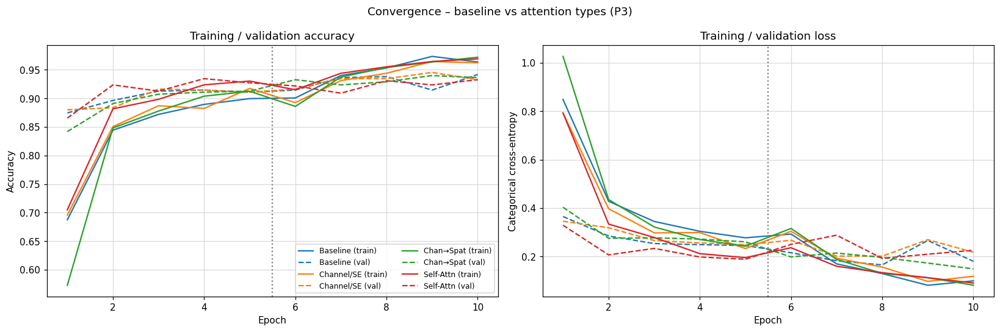

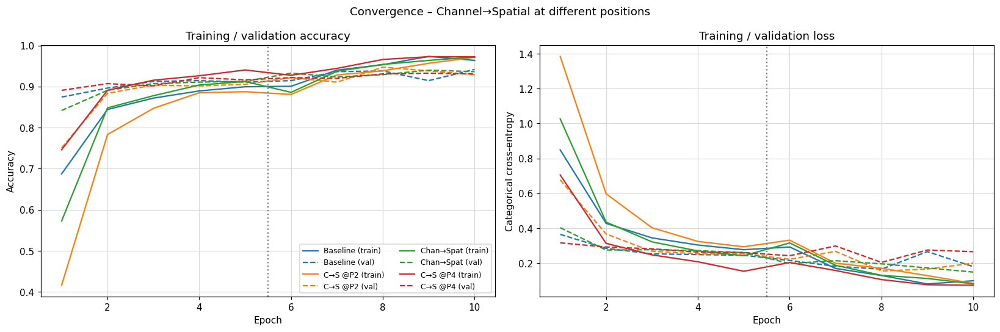

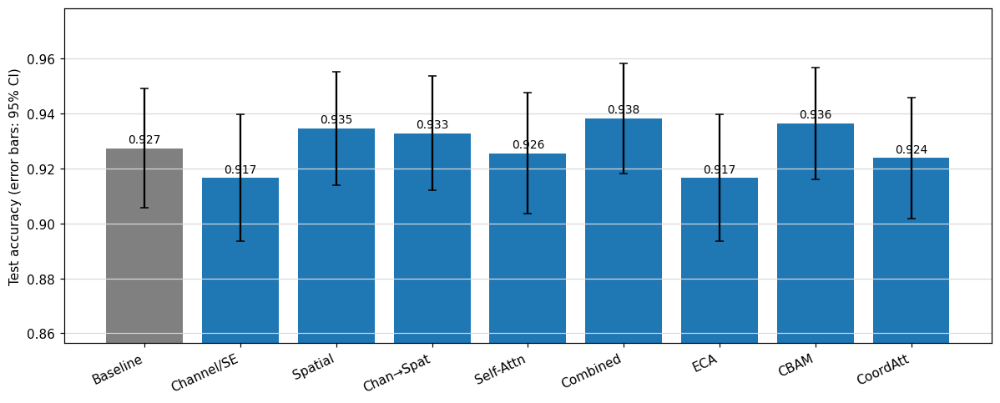

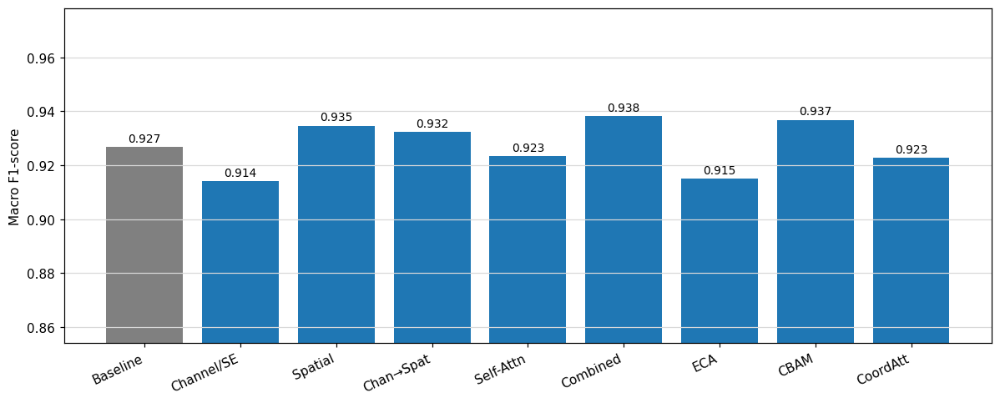

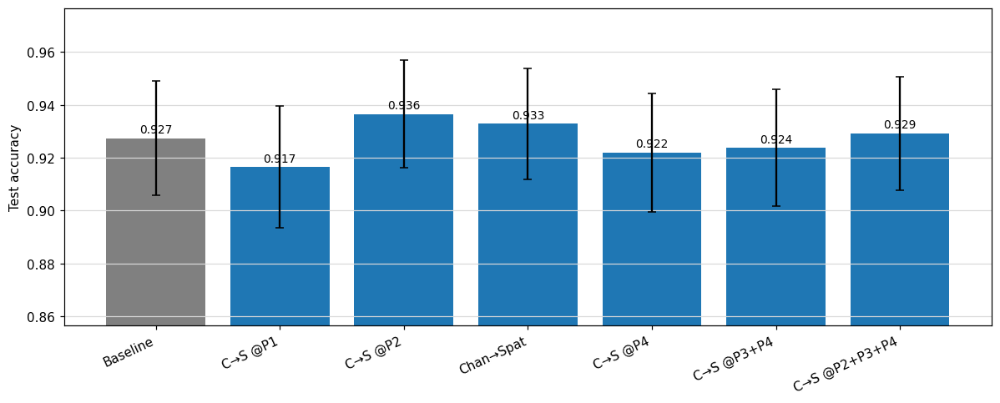

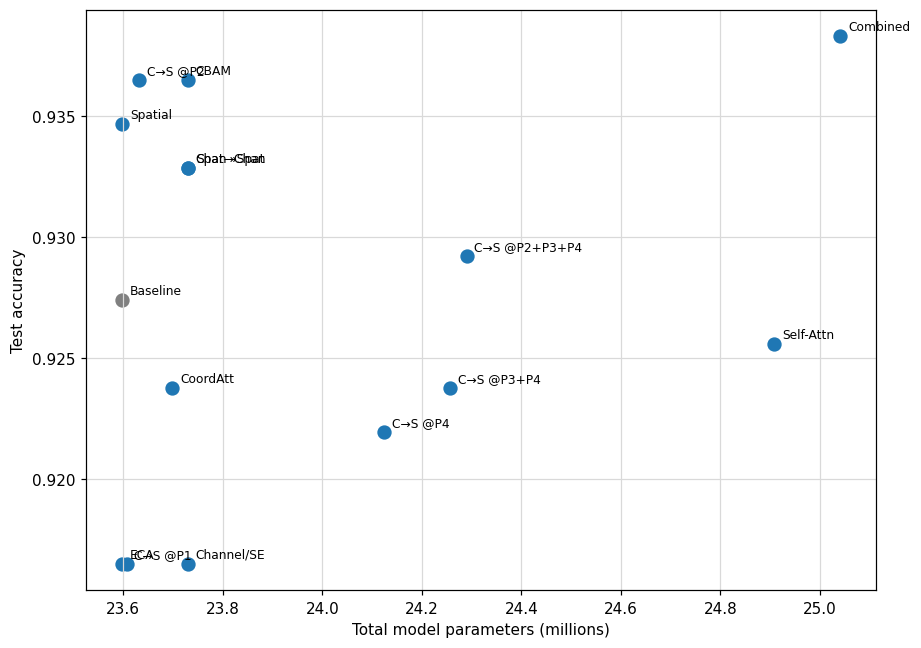

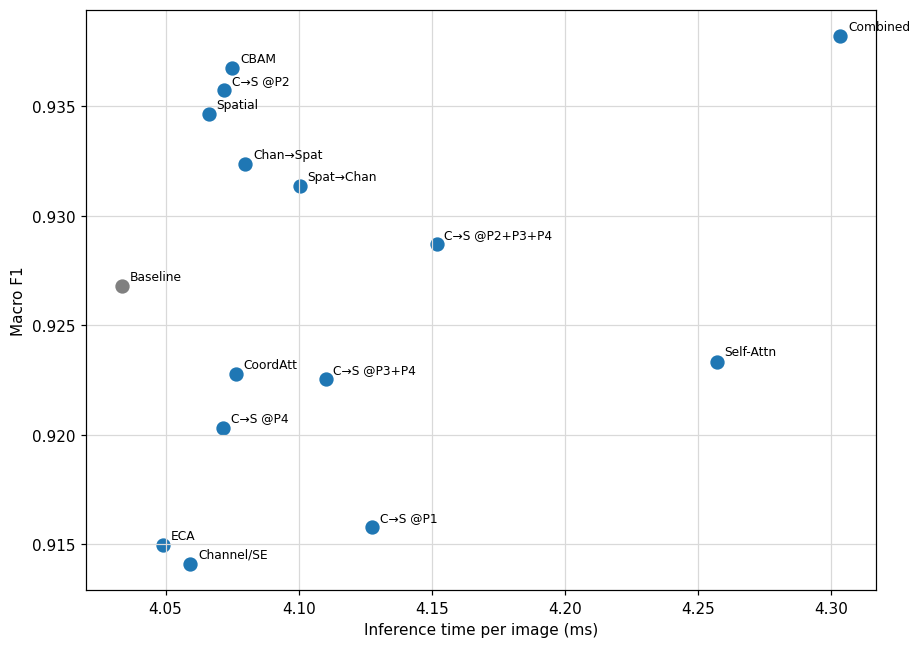

In [ ]:
def plot_curves(names, title, fname):
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    for i, n in enumerate(names):
        h, c = RESULTS[n]["history"], f"C{i}"; ep = np.arange(1, len(h["accuracy"]) + 1)
        ax[0].plot(ep, h["accuracy"], c=c, label=f"{LABEL[n]} (train)"); ax[0].plot(ep, h["val_accuracy"], c=c, ls="--", label=f"{LABEL[n]} (val)")
        ax[1].plot(ep, h["loss"], c=c, label=f"{LABEL[n]} (train)");     ax[1].plot(ep, h["val_loss"], c=c, ls="--", label=f"{LABEL[n]} (val)")
    for a, yl in zip(ax, ["Accuracy", "Categorical cross-entropy"]):
        a.axvline(EPOCHS_HEAD + 0.5, color="gray", ls=":"); a.set_xlabel("Epoch"); a.set_ylabel(yl); a.grid(color="0.85")
    ax[0].set_title("Training / validation accuracy"); ax[1].set_title("Training / validation loss")
    ax[0].legend(fontsize=8, ncol=2); plt.suptitle(title); plt.tight_layout()
    plt.savefig(f"{OUT}/figures/{fname}.eps", bbox_inches="tight", dpi=600, format="eps"); plt.show()

plot_curves(["A0_baseline", "A1_channel_P3", "A3_cs_P3", "A4_self_P3"], "Convergence – baseline vs attention types (P3)", "02_curves_types")
plot_curves(["A0_baseline", "B2_cs_P2", "A3_cs_P3", "B4_cs_P4"], "Convergence – Channel→Spatial at different positions", "03_curves_positions")

def bar(names, key, ylabel, fname, ylim=None):
    names = [n for n in names if n in RESULTS]
    vals = [RESULTS[n][key] for n in names]
    fig, ax = plt.subplots(figsize=(11, 4.5))
    b = ax.bar([LABEL[n] for n in names], vals, color=["gray" if n == "A0_baseline" else "C0" for n in names])
    if key == "test_acc":
        ax.errorbar(range(len(names)), vals, yerr=[RESULTS[n]["acc_ci95"] for n in names], fmt="none", ecolor="k", capsize=3)
    for r, v in zip(b, vals): ax.text(r.get_x() + r.get_width() / 2, v + 0.002, f"{v:.3f}", ha="center", fontsize=9)
    lo = min(vals); ax.set_ylim(ylim or (max(0, lo - 0.06), min(1.0, max(vals) + 0.04)))
    ax.set_ylabel(ylabel); ax.grid(axis="y", color="0.85"); plt.xticks(rotation=25, ha="right"); plt.tight_layout()
    plt.savefig(f"{OUT}/figures/{fname}.eps", bbox_inches="tight", dpi=600, format="eps"); plt.show()

MECH = ["A0_baseline", "A1_channel_P3", "A2_spatial_P3", "A3_cs_P3", "A4_self_P3", "A5_combined_P3", "X1_eca_P3", "X2_cbam_P3", "X3_coord_P3"]
bar(MECH, "test_acc", "Test accuracy (error bars: 95% CI)", "04_bar_accuracy")        # 24.3
bar(MECH, "f1", "Macro F1-score", "05_bar_f1")                                         # 24.4
bar(["A0_baseline", "B1_cs_P1", "B2_cs_P2", "A3_cs_P3", "B4_cs_P4", "C1_cs_P3P4", "C2_cs_P2P3P4"], "test_acc",
    "Test accuracy", "06_bar_positions")

def scatter(xkey, ykey, xl, yl, fname, scale=1.0):
    fig, ax = plt.subplots(figsize=(8.5, 6))
    for n in MECH + ["B1_cs_P1", "B2_cs_P2", "B4_cs_P4", "C1_cs_P3P4", "C2_cs_P2P3P4", "D1_sc_P3"]:
        if n not in RESULTS: continue
        r = RESULTS[n]; ax.scatter(r[xkey] * scale, r[ykey], s=70, color="gray" if n == "A0_baseline" else "C0")
        ax.annotate(LABEL[n], (r[xkey] * scale, r[ykey]), textcoords="offset points", xytext=(5, 4), fontsize=8)
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.grid(color="0.85"); plt.tight_layout()
    plt.savefig(f"{OUT}/figures/{fname}.eps", bbox_inches="tight", dpi=600, format="eps"); plt.show()

scatter("total_params", "test_acc", "Total model parameters (millions)", "Test accuracy", "07_acc_vs_params", 1e-6)   # 24.5
scatter("infer_ms", "f1", "Inference time per image (ms)", "Macro F1", "08_f1_vs_time")                              # 24.6

### 6.2 Confusion-matrix analysis

Selected attention model (best validation accuracy): C1_cs_P3P4 - C→S @P3+P4


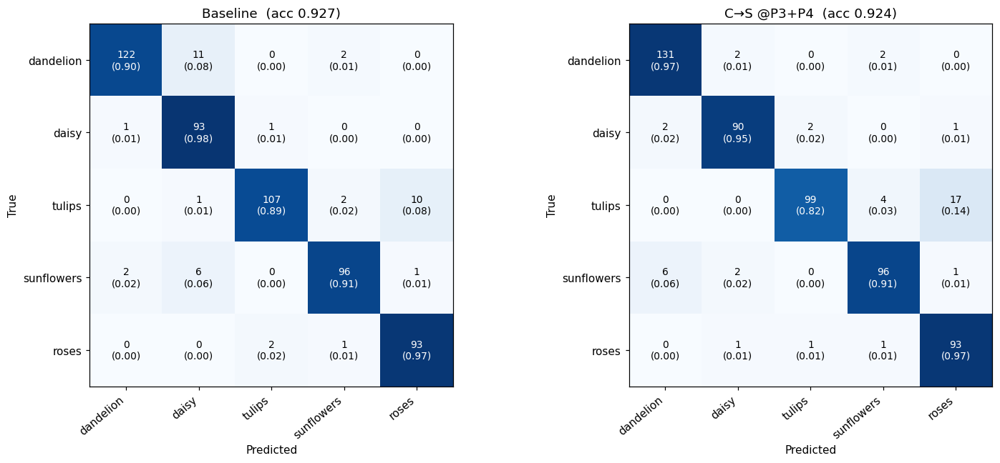

,baseline F1,C→S @P3+P4 F1,Δ F1
dandelion,0.9385,0.9562,+0.0177
daisy,0.9029,0.9474,+0.0445
tulips,0.9304,0.8919,-0.0385
sunflowers,0.9320,0.9231,-0.0090
roses,0.9300,0.8942,-0.0358


,true,predicted as,baseline count,attention count
0,dandelion,daisy,11,2
11,tulips,roses,10,17
13,sunflowers,daisy,6,2
2,dandelion,sunflowers,2,2
18,roses,tulips,2,1
10,tulips,sunflowers,2,4


              precision    recall  f1-score   support

   dandelion     0.9424    0.9704    0.9562       135
       daisy     0.9474    0.9474    0.9474        95
      tulips     0.9706    0.8250    0.8919       120
  sunflowers     0.9320    0.9143    0.9231       105
       roses     0.8304    0.9688    0.8942        96

    accuracy                         0.9238       551
   macro avg     0.9246    0.9252    0.9226       551
weighted avg     0.9279    0.9238    0.9236       551



In [ ]:
attn_names = [n for n in RESULTS if n != "A0_baseline"]
SELECTED = max(attn_names, key=lambda n: RESULTS[n]["best_val_acc"])
print("Selected attention model (best validation accuracy):", SELECTED, "-", LABEL[SELECTED])

def plot_cm(name, ax):
    cm = confusion_matrix(y_test, RESULTS[name]["y_pred"], labels=range(NUM_CLASSES)); cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, f"{cm[i, j]}\n({cmn[i, j]:.2f})", ha="center", va="center", fontsize=9, color="white" if cmn[i, j] > .5 else "black")
    ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=40, ha="right"); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{LABEL[name]}  (acc {RESULTS[name]['test_acc']:.3f})")

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
plot_cm("A0_baseline", ax[0]); plot_cm(SELECTED, ax[1]); plt.tight_layout()
plt.savefig(f"{OUT}/figures/09_confusion.eps", bbox_inches="tight", dpi=600, format="eps"); plt.show()

df = pd.DataFrame({"baseline F1": RESULTS["A0_baseline"]["per_class_f1"], f"{LABEL[SELECTED]} F1": RESULTS[SELECTED]["per_class_f1"]}, index=CLASS_NAMES)
df["Δ F1"] = df.iloc[:, 1] - df.iloc[:, 0]
display(df.style.format("{:+.4f}", subset=["Δ F1"]).format("{:.4f}", subset=df.columns[:2]))

# most frequent confusions
cm_b = confusion_matrix(y_test, RESULTS["A0_baseline"]["y_pred"]); cm_a = confusion_matrix(y_test, RESULTS[SELECTED]["y_pred"])
pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], cm_b[i, j], cm_a[i, j]) for i in range(5) for j in range(5) if i != j]
display(pd.DataFrame(pairs, columns=["true", "predicted as", "baseline count", "attention count"]).sort_values("baseline count", ascending=False).head(6))
print(classification_report(y_test, RESULTS[SELECTED]["y_pred"], target_names=CLASS_NAMES, digits=4))

## 7. Qualitative analysis

In [ ]:
def trained_model(name):
    m = build_model(EXPERIMENTS[name], name, weights=None)       # pretrained weights are overwritten by the saved ones
    m.load_weights(weights_path(name)); return m

def free(): keras.backend.clear_session(); gc.collect()

def norm01(m): m = np.asarray(m, dtype=np.float32); m = m - m.min(); return m / (m.max() + 1e-8)
def up(m):  # (h,w) -> (224,224) bilinear
    return tf.image.resize(np.asarray(m, dtype=np.float32)[None, ..., None], (IMG, IMG), method="bilinear").numpy()[0, ..., 0]
def overlay(ax, img, heat, alpha=0.5, title=None):
    """Heat-map overlay blended in RGB (EPS does not support transparency, so no imshow alpha)."""
    h = plt.get_cmap("jet")(norm01(up(heat)))[..., :3]
    ax.imshow((1 - alpha) * (np.asarray(img, dtype=np.float32) / 255.0) + alpha * h); ax.axis("off")
    if title: ax.set_title(title, fontsize=9)

def position_of(name): return int(list(EXPERIMENTS[name].keys())[0][1:])      # single-position models

def extract(model, k, x):
    """(feature map before attention_Pk, after attention_Pk) for a preprocessed batch x.
    The stages are run one by one. (stage_i.output is the sub-model's *inner* tensor, which is not
    connected to model.input in the outer graph, so keras.Model(model.input, stage.output) raises KeyError.)"""
    names = {l.name for l in model.layers}
    h = tf.convert_to_tensor(x)
    for i in range(1, k + 1):
        h = model.get_layer(f"stage{i}")(h, training=False)
        if i < k and f"attn_P{i}" in names:                       # earlier attention blocks (multi-position models)
            h = model.get_layer(f"attn_P{i}")(h, training=False)
    return h, model.get_layer(f"attn_P{k}")(h, training=False)

def gradcam_batch(model, xs):
    """Grad-CAM (Selvaraju et al.) of the predicted class for every image in xs. Returns (heatmaps 7x7, predictions)."""
    feat_model = keras.Model(model.input, model.get_layer("final_features").output)
    W, b = [tf.constant(w) for w in model.get_layer("classifier").get_weights()]
    heats, preds = [], []
    for i in range(len(xs)):
        with tf.GradientTape() as tape:
            fm = feat_model(xs[i:i + 1], training=False)
            logits = tf.matmul(tf.reduce_mean(fm, axis=[1, 2]), W) + b
            cls = int(tf.argmax(logits[0])); score = logits[0, cls]
        g = tape.gradient(score, fm)
        alpha = tf.reduce_mean(g, axis=[1, 2], keepdims=True)                       # α_k^c
        heats.append(tf.nn.relu(tf.reduce_sum(alpha * fm, axis=-1))[0].numpy()); preds.append(cls)
    return np.stack(heats), np.array(preds)

# ---------- choose representative test images ----------
pred_base, pred_sel = np.array(RESULTS["A0_baseline"]["y_pred"]), np.array(RESULTS[SELECTED]["y_pred"])
rng = np.random.RandomState(1)
both_ok = np.where((pred_base == y_test) & (pred_sel == y_test))[0]
correct_idx = []
for c in rng.permutation(NUM_CLASSES):                                   # 3 correctly classified images from 3 different classes
    cand = both_ok[y_test[both_ok] == c]
    if len(cand) and len(correct_idx) < 3: correct_idx.append(int(rng.choice(cand)))
wrong = np.where((pred_sel != y_test) | (pred_base != y_test))[0]
wrong_idx = [int(i) for i in rng.permutation(wrong)[:2]]                 # 2 images misclassified by at least one model
QUAL_IDX = correct_idx + wrong_idx
print("Correct:", correct_idx, "| Misclassified (by baseline and/or selected model):", wrong_idx)
for i in QUAL_IDX:
    print(f"  test[{i}] true={CLASS_NAMES[y_test[i]]:<10} baseline={CLASS_NAMES[pred_base[i]]:<10} {LABEL[SELECTED]}={CLASS_NAMES[pred_sel[i]]}")
XQ_raw, XQ = X_test[QUAL_IDX], prep(X_test[QUAL_IDX])

Correct: [35, 452, 38] | Misclassified (by baseline and/or selected model): [476, 507]
  test[35] true=tulips     baseline=tulips     C→S @P3+P4=tulips
  test[452] true=daisy      baseline=daisy      C→S @P3+P4=daisy
  test[38] true=roses      baseline=roses      C→S @P3+P4=roses
  test[476] true=tulips     baseline=roses      C→S @P3+P4=roses
  test[507] true=roses      baseline=tulips     C→S @P3+P4=roses


### 7.1 Feature maps before / after attention, channel weights, spatial heat-map and overlay

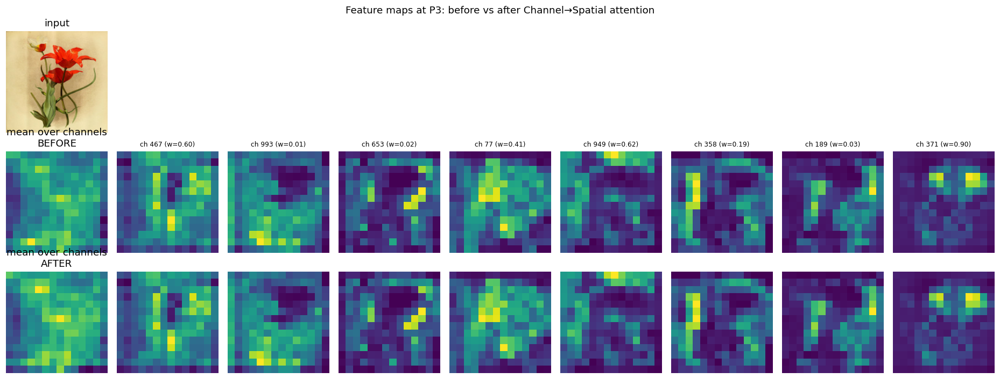

Mean activation before: 0.486 | after: 0.286  (attention is a soft gate, values ≤ input)


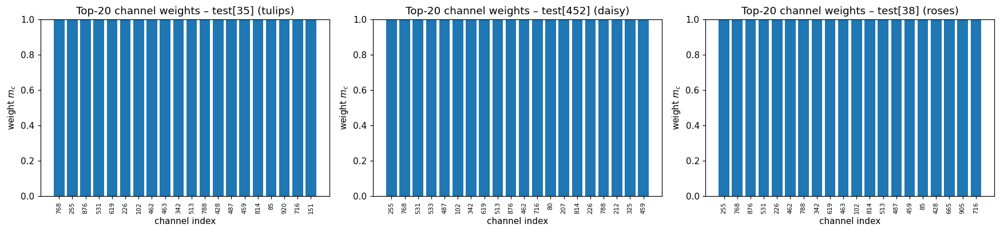

channel weights: mean 0.592, std 0.407, fraction > 0.5 : 59.75%
Top-20 overlap (Jaccard) between different images: 0.75  (1 = same channels always favoured)


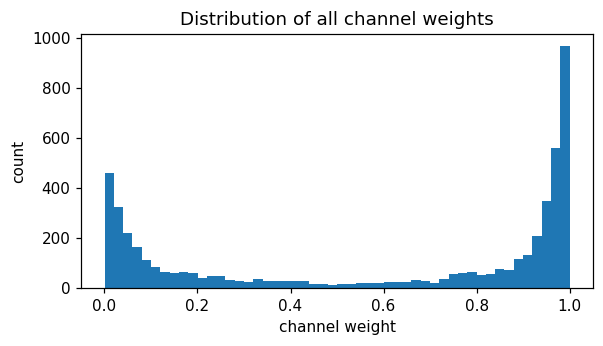

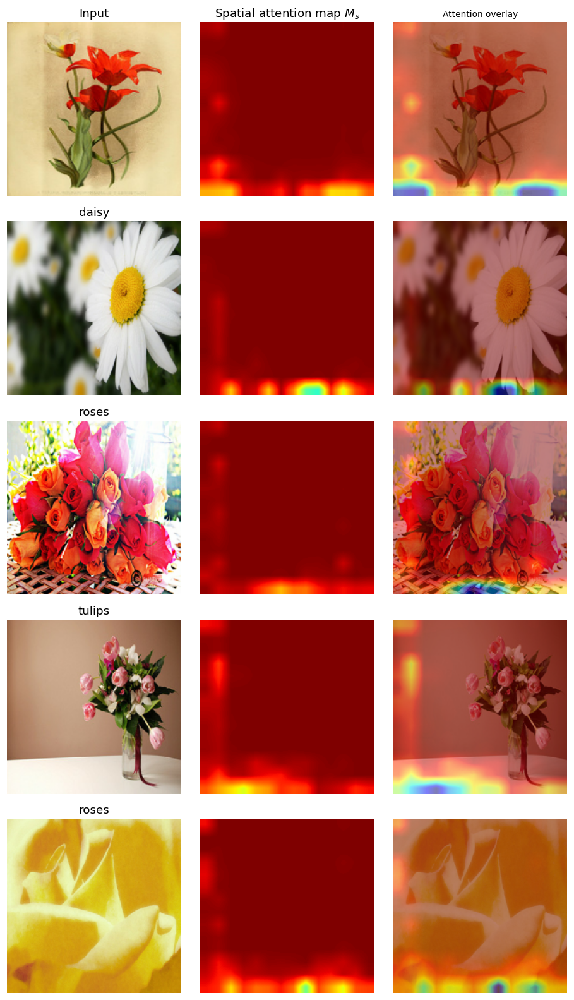

Spatial-attention values  min/mean/max: 0.403 / 0.979 / 1.000


In [ ]:
NAME = "A3_cs_P3"; K = position_of(NAME)
m = trained_model(NAME); att = m.get_layer(f"attn_P{K}")
fb, fa = extract(m, K, XQ)
cw  = att.channel_weights(fb).numpy()                 # (n, C)
sm  = att.spatial_map(fb).numpy()[..., 0]             # (n, H, W)
g_attn = gradcam_batch(m, XQ)[0]
del m; free()

# (a) feature maps before / after attention  (channel-mean + 8 strongest channels)
i0 = 0
fig, ax = plt.subplots(3, 9, figsize=(17, 6.5))
top8 = np.argsort(-fb[i0].numpy().mean((0, 1)))[:8]
ax[0, 0].imshow(XQ_raw[i0]); ax[0, 0].set_title("input");
ax[1, 0].imshow(fb[i0].numpy().mean(-1), cmap="viridis"); ax[1, 0].set_title("mean over channels\nBEFORE")
ax[2, 0].imshow(fa[i0].numpy().mean(-1), cmap="viridis"); ax[2, 0].set_title("mean over channels\nAFTER")
for j, ch in enumerate(top8, 1):
    ax[0, j].axis("off")
    ax[1, j].imshow(fb[i0].numpy()[..., ch], cmap="viridis"); ax[1, j].set_title(f"ch {ch} (w={cw[i0, ch]:.2f})", fontsize=8)
    ax[2, j].imshow(fa[i0].numpy()[..., ch], cmap="viridis")
for a in ax.ravel(): a.axis("off")
plt.suptitle(f"Feature maps at P{K}: before vs after Channel→Spatial attention"); plt.tight_layout()
plt.savefig(f"{OUT}/figures/10_featuremaps.eps", bbox_inches="tight", dpi=600, format="eps"); plt.show()
print(f"Mean activation before: {fb[i0].numpy().mean():.3f} | after: {fa[i0].numpy().mean():.3f}  (attention is a soft gate, values ≤ input)")

# (b) channel-attention weights: top-K channels per image
KTOP = 20
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, i in zip(ax, range(3)):
    top = np.argsort(-cw[i])[:KTOP]
    a.bar(range(KTOP), cw[i, top]); a.set_xticks(range(KTOP)); a.set_xticklabels(top, rotation=90, fontsize=7)
    a.set_title(f"Top-{KTOP} channel weights – test[{QUAL_IDX[i]}] ({CLASS_NAMES[y_test[QUAL_IDX[i]]]})"); a.set_ylim(0, 1); a.set_xlabel("channel index"); a.set_ylabel("weight $m_c$")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/11_channel_weights.eps", bbox_inches="tight", dpi=600, format="eps"); plt.show()

# do a few channels dominate? does the weighting change with the image?
tops = [set(np.argsort(-cw[i])[:KTOP]) for i in range(len(cw))]
jac = np.mean([len(tops[i] & tops[j]) / len(tops[i] | tops[j]) for i in range(len(tops)) for j in range(i + 1, len(tops))])
print(f"channel weights: mean {cw.mean():.3f}, std {cw.std():.3f}, fraction > 0.5 : {(cw > .5).mean():.2%}")
print(f"Top-{KTOP} overlap (Jaccard) between different images: {jac:.2f}  (1 = same channels always favoured)")
fig, ax = plt.subplots(figsize=(6, 3)); ax.hist(cw.ravel(), bins=50); ax.set_xlabel("channel weight"); ax.set_ylabel("count"); ax.set_title("Distribution of all channel weights"); plt.show()

# (c) spatial attention heat-map and overlay
fig, ax = plt.subplots(len(QUAL_IDX), 3, figsize=(8.5, 2.9 * len(QUAL_IDX)))
for r, i in enumerate(range(len(QUAL_IDX))):
    ax[r, 0].imshow(XQ_raw[i]); ax[r, 0].axis("off"); ax[r, 0].set_title(f"{CLASS_NAMES[y_test[QUAL_IDX[i]]]}" if r else "Input")
    im = ax[r, 1].imshow(up(sm[i]), cmap="jet", vmin=0, vmax=1); ax[r, 1].axis("off")
    if r == 0: ax[r, 1].set_title("Spatial attention map $M_s$")
    overlay(ax[r, 2], XQ_raw[i], sm[i], title="Attention overlay" if r == 0 else None)
plt.tight_layout(); plt.savefig(f"{OUT}/figures/12_spatial_attention.eps", bbox_inches="tight", dpi=600, format="eps"); plt.show()
print("Spatial-attention values  min/mean/max:", f"{sm.min():.3f} / {sm.mean():.3f} / {sm.max():.3f}")

### 7.2 Self-attention response

learned gamma = -0.0236   |  attention matrix per image: 196×196


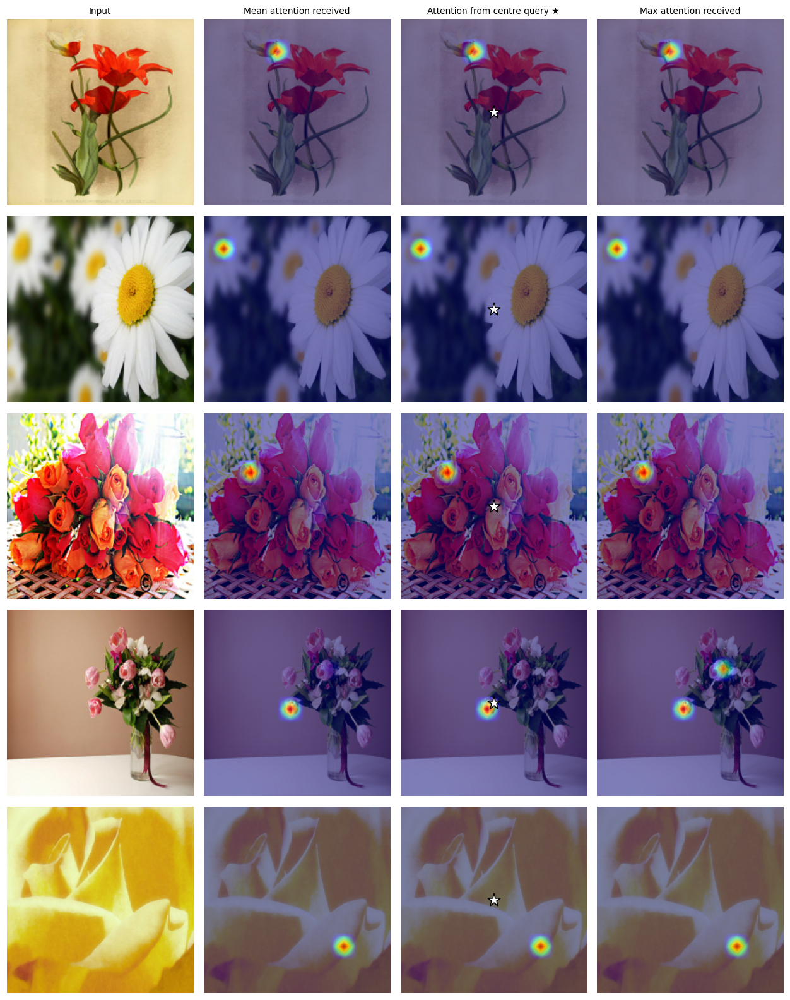

mean attention-row entropy 0.04 nats (uniform over 196 positions = 5.28; lower = more focused)


In [ ]:
NAME = "A4_self_P3"; K = position_of(NAME)
m = trained_model(NAME); att = m.get_layer(f"attn_P{K}")
fb, _ = extract(m, K, XQ)
Amat = att.attention_matrix(fb).numpy()                      # (n, N, N)
gamma = float(att.gamma.numpy()); H = W = int(math.sqrt(Amat.shape[1]))
del m; free()
print(f"learned gamma = {gamma:.4f}   |  attention matrix per image: {Amat.shape[1]}×{Amat.shape[2]}")

q = (H // 2) * W + W // 2
fig, ax = plt.subplots(len(QUAL_IDX), 4, figsize=(11.5, 2.9 * len(QUAL_IDX)))
for r in range(len(QUAL_IDX)):
    a = Amat[r]
    ax[r, 0].imshow(XQ_raw[r]); ax[r, 0].axis("off")
    overlay(ax[r, 1], XQ_raw[r], a.mean(0).reshape(H, W))
    overlay(ax[r, 2], XQ_raw[r], a[q].reshape(H, W)); ax[r, 2].plot(IMG // 2, IMG // 2, "w*", ms=14, mec="k")
    overlay(ax[r, 3], XQ_raw[r], a.max(0).reshape(H, W))
for a_, t in zip(ax[0], ["Input", "Mean attention received", "Attention from centre query ★", "Max attention received"]): a_.set_title(t, fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT}/figures/13_self_attention.eps", bbox_inches="tight", dpi=600, format="eps"); plt.show()
ent = -(Amat * np.log(Amat + 1e-12)).sum(-1).mean()
print(f"mean attention-row entropy {ent:.2f} nats (uniform over {H*W} positions = {math.log(H*W):.2f}; lower = more focused)")

### 7.3 Attention at different depths

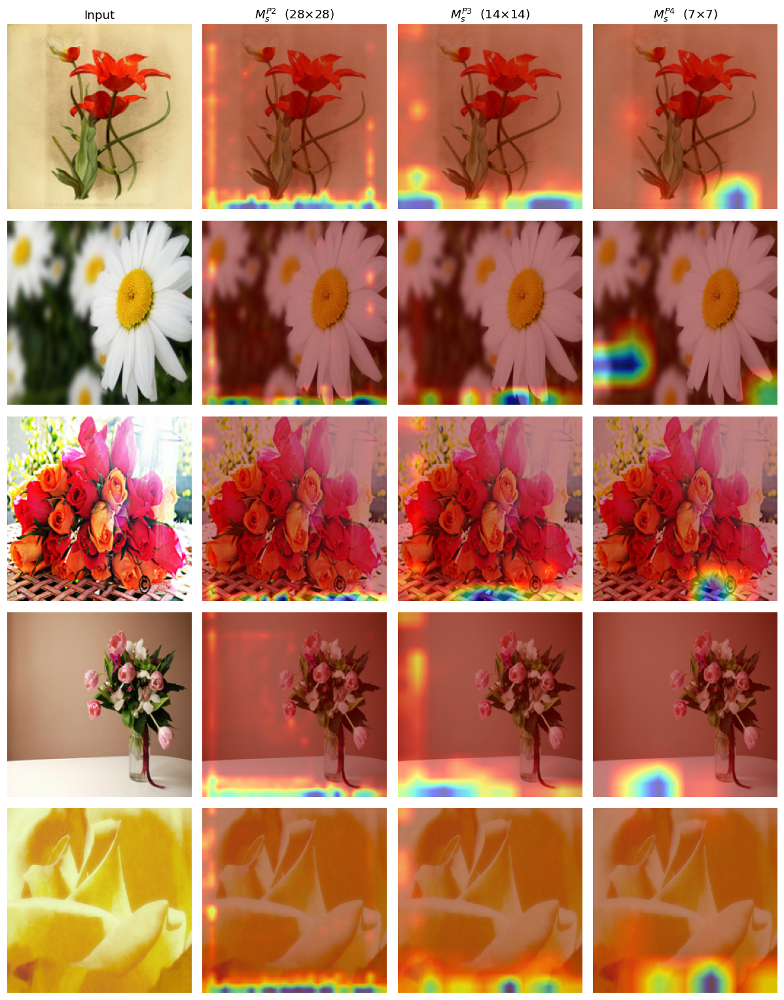

P2: mean 0.967, std over locations 0.100, min 0.150, max 1.000
P3: mean 0.979, std over locations 0.059, min 0.403, max 1.000
P4: mean 0.988, std over locations 0.052, min 0.168, max 1.000


In [ ]:
pos_models = {2: "B2_cs_P2", 3: "A3_cs_P3", 4: "B4_cs_P4"}
pos_maps = {}
for k, n in pos_models.items():
    m = trained_model(n); fb, _ = extract(m, k, XQ)
    pos_maps[k] = m.get_layer(f"attn_P{k}").spatial_map(fb).numpy()[..., 0]; del m; free()

fig, ax = plt.subplots(len(QUAL_IDX), 4, figsize=(11, 2.8 * len(QUAL_IDX)))
for r in range(len(QUAL_IDX)):
    ax[r, 0].imshow(XQ_raw[r]); ax[r, 0].axis("off")
    for c, k in enumerate([2, 3, 4], 1):
        overlay(ax[r, c], XQ_raw[r], pos_maps[k][r])
        if r == 0: ax[r, c].set_title(f"$M_s^{{P{k}}}$  ({pos_maps[k].shape[1]}×{pos_maps[k].shape[2]})")
ax[0, 0].set_title("Input")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/14_attention_positions.eps", bbox_inches="tight", dpi=600, format="eps"); plt.show()
for k in pos_maps:
    mp = pos_maps[k]; print(f"P{k}: mean {mp.mean():.3f}, std over locations {mp.std(axis=(1,2)).mean():.3f}, min {mp.min():.3f}, max {mp.max():.3f}")

### 7.4 Grad-CAM: baseline vs attention models, and the qualitative comparison grids

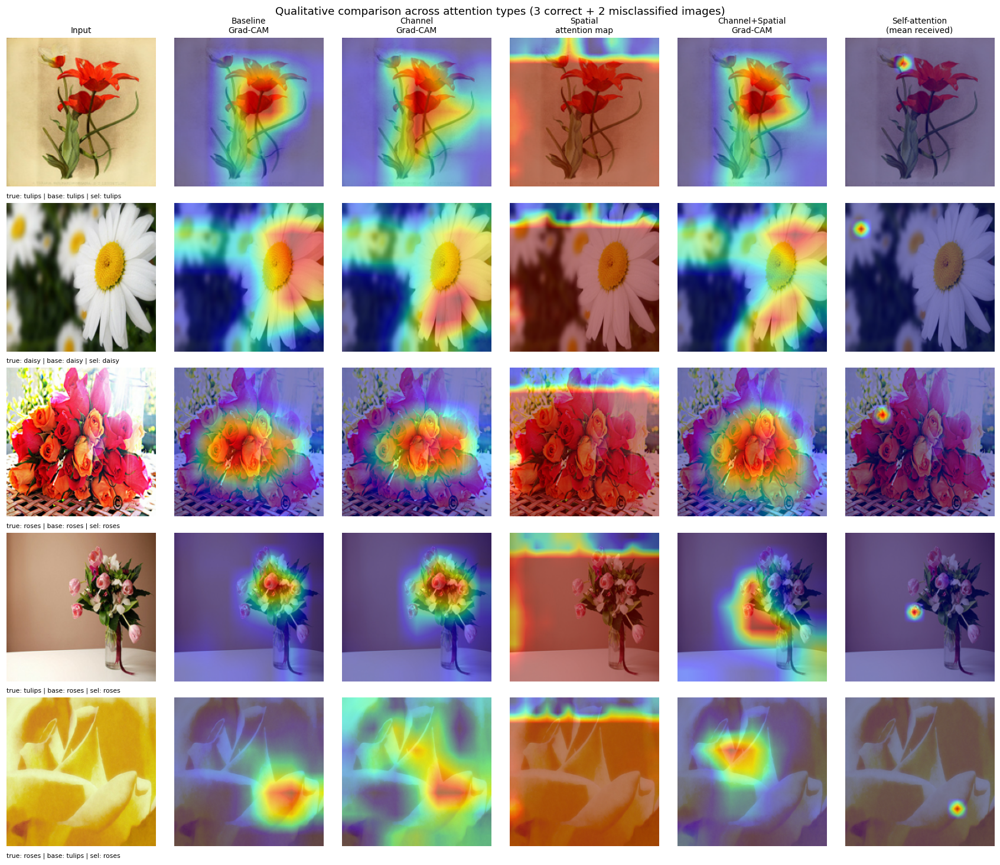

In [ ]:
def qual_grid(columns, idxs, fname, suptitle=""):
    """columns: list of (title, experiment_name or None, kind) with kind in {'input','gradcam','spatial','selfattn'}."""
    xr, xp = X_test[idxs], prep(X_test[idxs]); cols = []
    for title, name, kind in columns:
        if kind == "input": cols.append(None); continue
        m = trained_model(name); k = position_of(name) if kind != "gradcam" else None
        if kind == "gradcam":
            heats, _ = gradcam_batch(m, xp)
        else:
            fb, _ = extract(m, k, xp); att = m.get_layer(f"attn_P{k}")
            if kind == "spatial": heats = att.spatial_map(fb).numpy()[..., 0]
            else: heats = att.attention_matrix(fb).numpy().mean(1).reshape(len(idxs), fb.shape[1], fb.shape[2])
        cols.append(heats); del m; free()
    fig, ax = plt.subplots(len(idxs), len(columns), figsize=(2.6 * len(columns), 2.7 * len(idxs)))
    for r, i in enumerate(idxs):
        for c, (title, name, kind) in enumerate(columns):
            if kind == "input": ax[r, c].imshow(xr[r]); ax[r, c].axis("off")
            else: overlay(ax[r, c], xr[r], cols[c][r])
            if r == 0: ax[r, c].set_title(title, fontsize=9)
        ax[r, 0].text(0, -0.04, f"true: {CLASS_NAMES[y_test[i]]} | base: {CLASS_NAMES[pred_base[i]]} | sel: {CLASS_NAMES[pred_sel[i]]}",
                      transform=ax[r, 0].transAxes, fontsize=7, va="top")
    plt.suptitle(suptitle); plt.tight_layout(); plt.savefig(f"{OUT}/figures/{fname}.eps", bbox_inches="tight", dpi=600, format="eps"); plt.show()

# Section 32 layout: Input | Baseline GC | Channel GC | Spatial map | Channel+Spatial GC | Self-attention response
qual_grid([("Input", None, "input"), ("Baseline\nGrad-CAM", "A0_baseline", "gradcam"), ("Channel\nGrad-CAM", "A1_channel_P3", "gradcam"),
           ("Spatial\nattention map", "A2_spatial_P3", "spatial"), ("Channel+Spatial\nGrad-CAM", "A3_cs_P3", "gradcam"),
           ("Self-attention\n(mean received)", "A4_self_P3", "selfattn")], QUAL_IDX, "15_qualitative_main",
          "Qualitative comparison across attention types (3 correct + 2 misclassified images)")

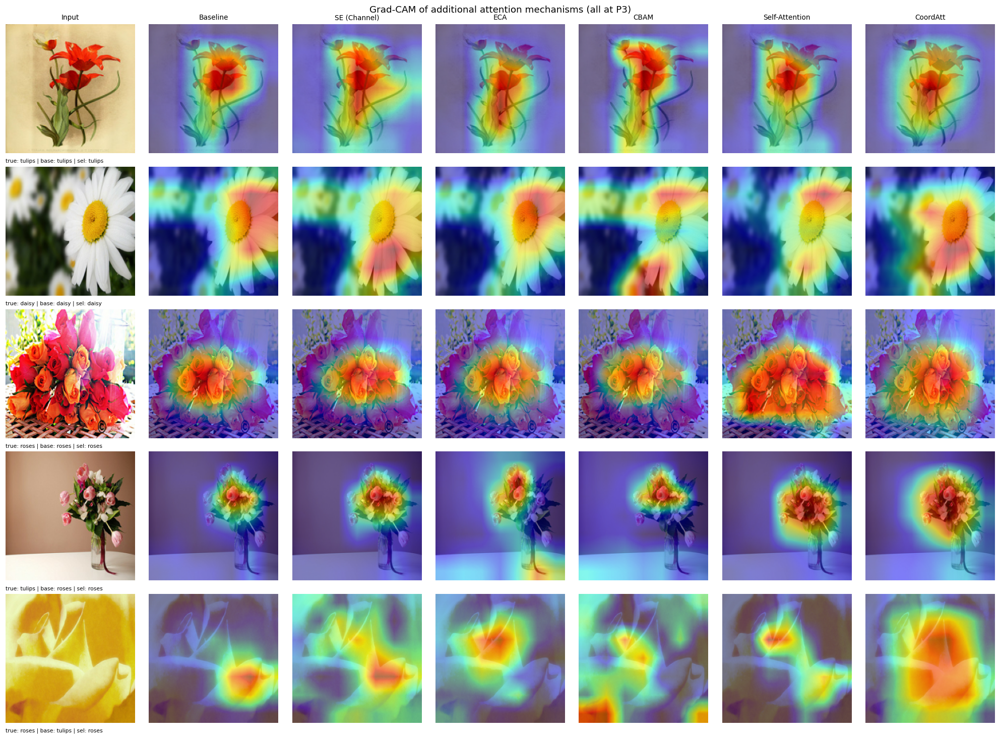

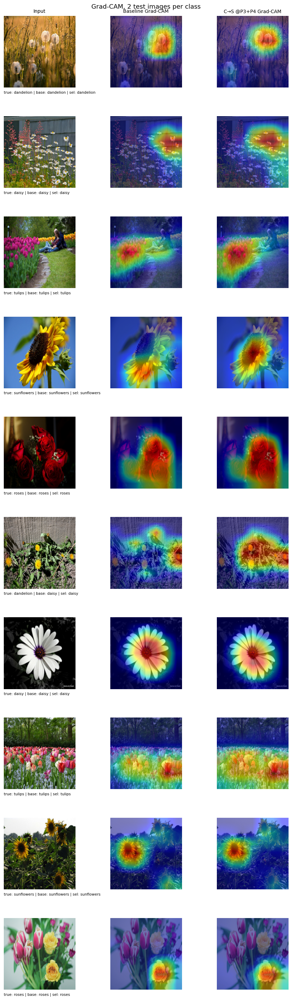

In [ ]:
# Extended layout for the additional-attention task: Input | Baseline | SE | ECA | CBAM | Self-Attention (all Grad-CAM)
qual_grid([("Input", None, "input"), ("Baseline", "A0_baseline", "gradcam"), ("SE (Channel)", "A1_channel_P3", "gradcam"),
           ("ECA", "X1_eca_P3", "gradcam"), ("CBAM", "X2_cbam_P3", "gradcam"), ("Self-Attention", "A4_self_P3", "gradcam"),
           ("CoordAtt", "X3_coord_P3", "gradcam")], QUAL_IDX, "16_qualitative_extended", "Grad-CAM of additional attention mechanisms (all at P3)")

# Grad-CAM for the selected model vs baseline on more images (one per class) - avoid conclusions from a single image
per_class = [int(np.where(y_test == c)[0][0]) for c in range(NUM_CLASSES)] + [int(np.where(y_test == c)[0][1]) for c in range(NUM_CLASSES)]
qual_grid([("Input", None, "input"), ("Baseline Grad-CAM", "A0_baseline", "gradcam"), (f"{LABEL[SELECTED]} Grad-CAM", SELECTED, "gradcam")],
          per_class, "17_gradcam_per_class", "Grad-CAM, 2 test images per class")

#### 7.5 A simple *quantitative* proxy for background suppression

In [ ]:
def cam_stats(name, n=200):
    idx = np.random.RandomState(0).choice(len(y_test), n, replace=False)
    m = trained_model(name); heats, _ = gradcam_batch(m, prep(X_test[idx])); del m; free()
    conc, cover = [], []
    for h in heats:
        u = norm01(up(h)).ravel(); s = np.sort(u)[::-1]
        conc.append(s[: len(s) // 5].sum() / (s.sum() + 1e-8)); cover.append((u > 0.5).mean())
    return np.mean(conc), np.mean(cover)

rows = []
for n in ["A0_baseline", "A1_channel_P3", "A2_spatial_P3", "A3_cs_P3", "A4_self_P3", "X1_eca_P3", "X2_cbam_P3", "X3_coord_P3"]:
    if n in RESULTS:
        c, v = cam_stats(n); rows.append({"Model": LABEL[n], "mass in top-20% pixels": c, "coverage (>0.5)": v})
display(pd.DataFrame(rows).set_index("Model").style.format("{:.3f}"))

,mass in top-20% pixels,coverage (>0.5)
Model,,
Baseline,0.560,0.189
Channel/SE,0.570,0.209
Spatial,0.575,0.177
Chan→Spat,0.582,0.177
Self-Attn,0.483,0.234
ECA,0.561,0.199
CBAM,0.571,0.196
CoordAtt,0.429,0.330


### 8.1 Automatic result summary

In [ ]:
from scipy.stats import spearmanr
R = RESULTS; base = R["A0_baseline"]; ci = base["acc_ci95"]
def d(n, k="test_acc"): return R[n][k] - base[k]

print(f"Baseline: acc {base['test_acc']:.4f} (±{ci:.3f}), macro-F1 {base['f1']:.4f}\n")
print("Δ vs baseline (accuracy | macro-F1 | Δparams | Δms/img), sorted by accuracy:")
for n in sorted((n for n in R if n != "A0_baseline"), key=lambda n: -R[n]["test_acc"]):
    flag = "" if abs(d(n)) > ci else "   (within ±CI of baseline → not a clear difference)"
    print(f"  {LABEL[n]:<16} {d(n):+.4f} | {d(n,'f1'):+.4f} | {R[n]['total_params']-base['total_params']:>+11,} | {R[n]['infer_ms']-base['infer_ms']:+.2f}{flag}")

def best_of(names, key="test_acc"):
    names = [n for n in names if n in R]; return max(names, key=lambda n: R[n][key]) if names else None
print("\nBest attention type @P3        :", LABEL[best_of(['A1_channel_P3','A2_spatial_P3','A3_cs_P3','A4_self_P3','A5_combined_P3','X1_eca_P3','X2_cbam_P3','X3_coord_P3'])])
print("Best position (C→S)            :", LABEL[best_of(['B1_cs_P1','B2_cs_P2','A3_cs_P3','B4_cs_P4'])])
print("Best single vs multi-position  :", LABEL[best_of(['A3_cs_P3','B4_cs_P4','C1_cs_P3P4','C2_cs_P2P3P4'])])
print(f"Order: C→S {R['A3_cs_P3']['test_acc']:.4f} vs S→C {R['D1_sc_P3']['test_acc']:.4f}")
print("Kernel size acc:", {k: round(R[n]['test_acc'], 4) for k, n in [(3,'E1_cs_k3_P3'),(5,'E2_cs_k5_P3'),(7,'A3_cs_P3')]})

names = list(R); rho, p = spearmanr([R[n]["total_params"] for n in names], [R[n]["test_acc"] for n in names])
print(f"\nSpearman(total params, accuracy) = {rho:+.2f} (p={p:.2f}) over {len(names)} models → "
      f"{'no reliable monotone link' if p > 0.05 else 'there is a monotone link'}")
rho, p = spearmanr([R[n]["infer_ms"] for n in names], [R[n]["f1"] for n in names])
print(f"Spearman(inference time, macro-F1) = {rho:+.2f} (p={p:.2f})")
print("\nConvergence: epochs needed to reach 90% validation accuracy")
for n in ["A0_baseline", "A1_channel_P3", "A2_spatial_P3", "A3_cs_P3", "A4_self_P3", "X2_cbam_P3"]:
    v = np.array(R[n]["history"]["val_accuracy"]); e = np.argmax(v >= 0.90) + 1 if (v >= 0.90).any() else None
    gap = R[n]["history"]["accuracy"][-1] - R[n]["history"]["val_accuracy"][-1]
    print(f"  {LABEL[n]:<14} first epoch ≥0.90: {e}   final train−val gap: {gap:+.3f}")

Baseline: acc 0.9274 (±0.022), macro-F1 0.9268

Δ vs baseline (accuracy | macro-F1 | Δparams | Δms/img), sorted by accuracy:
  C→S k=5          +0.0181 | +0.0180 |    +132,211 | +0.04   (within ±CI of baseline → not a clear difference)
  Combined         +0.0109 | +0.0114 |  +1,442,980 | +0.27   (within ±CI of baseline → not a clear difference)
  C→S @P2          +0.0091 | +0.0089 |     +33,411 | +0.04   (within ±CI of baseline → not a clear difference)
  CBAM             +0.0091 | +0.0100 |    +132,259 | +0.04   (within ±CI of baseline → not a clear difference)
  Spatial          +0.0073 | +0.0079 |         +99 | +0.03   (within ±CI of baseline → not a clear difference)
  Chan→Spat        +0.0054 | +0.0056 |    +132,259 | +0.05   (within ±CI of baseline → not a clear difference)
  Spat→Chan        +0.0054 | +0.0046 |    +132,259 | +0.07   (within ±CI of baseline → not a clear difference)
  C→S @P2+P3+P4    +0.0018 | +0.0019 |    +692,233 | +0.12   (within ±CI of baseline → not a clear